# Evaluating River clustering on a KDDCup99 stream: execution time & RAM usage

This notebook focuses on **online clustering** — the module of interest — and measures **execution time** and **memory footprint** as each clusterer learns from a real-world data stream.

Key idea of online ML: there is no separate "train" then "deploy" phase. Each sample is first **assigned to a cluster**, then **learned** — exactly how a production stream behaves. River's `evaluate.iter_progressive_val_score` replays a dataset one sample at a time using this *progressive (prequential) validation* protocol, and reports a cumulative `Time` and the model's `Memory` (`model._raw_memory_usage` — the size of the model object itself, not the whole process) at regular checkpoints.

We stream the **KDDCup99 HTTP** subset (network-intrusion detection, 567,498 connection records, 3 numeric features). The goal here is purely **resource profiling**: how does each clusterer's runtime and memory scale as the stream grows?

In [65]:
from __future__ import annotations

import itertools
import warnings

import matplotlib.pyplot as plt
import pandas as pd

from river import (
    cluster,
    datasets,
    evaluate,
    linear_model,
    metrics,
    preprocessing,
)
from river.utils.pretty import humanize_bytes

warnings.filterwarnings("ignore")
plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3

## 1. The dataset (the stream)

`datasets.HTTP()` is the HTTP subset of the KDDCup99 network-intrusion benchmark; each sample is a connection record with three numeric features (`duration`, `src_bytes`, `dst_bytes`). In a real project this would be a live network-traffic feed. We stream it one record at a time, exactly as a production system would.

The dataset is large, so we cap it with `N_SAMPLES` to keep the notebook responsive — raise it (or set `None`) to stream more."

In [66]:
N_SAMPLES = None  # KDDCup99 HTTP has 567,498; set to None to stream the full dataset
N_CHECKPOINTS = 40  # how many (time, memory) measurements per model


def make_dataset():
    """Fresh iterator over the stream, optionally capped at N_SAMPLES."""
    stream = datasets.HTTP()
    if N_SAMPLES is not None:
        return itertools.islice(stream, N_SAMPLES)
    return stream


n_stream = N_SAMPLES or datasets.HTTP().n_samples
step = max(1, n_stream // N_CHECKPOINTS)

print(f"Streaming {n_stream:,} samples, checkpoint every {step} samples")

x0, y0 = next(iter(datasets.HTTP()))
print("Example x:", x0)
print("Example y (label, hidden from the clusterer):", y0)

Streaming 567,498 samples, checkpoint every 14187 samples
Example x: {'duration': -2.302585092994045, 'src_bytes': 5.371103036273683, 'dst_bytes': 10.716107451545245}
Example y (label, hidden from the clusterer): 0


## 2. The clusterers

Four online clusterers from `river.cluster`, spanning different strategies:

- **STREAMKMeans** — streaming k-means designed for data streams: it buffers samples in small chunks and folds their local centroids into a running k-means, rather than revisiting past data.
- **CluStream** — keeps many *micro-clusters* then aggregates into macro-clusters (heavier in memory).
- **DBSTREAM** — density-based, discovers the number of clusters on its own.
- **DenStream** — density-based with fading, good for evolving streams.

Each is wrapped in a `StandardScaler` so all features live on the same scale. In production you'd pick **one**; we run all four only to compare resource profiles.

In [67]:
class StreamKMeansSafe(cluster.STREAMKMeans):
    """STREAMKMeans that tolerates being asked to predict before its first
    chunk has filled. Vanilla STREAMKMeans only creates centers once
    ``chunk_size`` samples have arrived, but progressive validation calls
    ``predict_one`` on the very first sample — so we return cluster 0 until
    centers exist. Behaviour is identical once the model has warmed up.
    """

    def predict_one(self, x, w=None):
        if not self.centers:
            return 0
        return super().predict_one(x, w)


def build_clusterers():
    """Return fresh clusterer instances (each run starts from a clean state)."""
    return {
        "STREAMKMeans": preprocessing.StandardScaler()
        | StreamKMeansSafe(n_clusters=2, seed=42),
        "CluStream": preprocessing.StandardScaler()
        | cluster.CluStream(n_macro_clusters=2, seed=42),
        "DBSTREAM": preprocessing.StandardScaler() | cluster.DBSTREAM(),
        "DenStream": preprocessing.StandardScaler() | cluster.DenStream(),
    }


list(build_clusterers())

['STREAMKMeans', 'CluStream', 'DBSTREAM', 'DenStream']

## 3. Stream each clusterer and record time + RAM

`iter_progressive_val_score` yields a dict at every checkpoint. With `measure_time=True` and `measure_memory=True` it includes `Step`, `Time` (a `timedelta`), and `Memory` (bytes). We ignore predictive quality here — the focus is purely on **how much time and memory** each clusterer consumes as the stream grows. A metric is still required by the API, so we pass a cheap one and don't read it.

In [68]:
def run_model(name, model):
    """Stream the dataset through a model, collecting time + memory at checkpoints."""
    rows = []
    steps = evaluate.iter_progressive_val_score(
        dataset=make_dataset(),
        model=model,
        metric=metrics.AdjustedRand(),  # required by the API; we don't read it
        step=step,
        measure_time=True,
        measure_memory=True,
    )
    for checkpoint in steps:
        rows.append(
            {
                "model": name,
                "step": checkpoint["Step"],
                "time_s": checkpoint["Time"].total_seconds(),
                "memory_bytes": checkpoint["Memory"],
            }
        )
    return rows


records = []
for name, model in build_clusterers().items():
    print(f"Streaming through {name} ...", end=" ", flush=True)
    model_rows = run_model(name, model)
    records.extend(model_rows)
    last = model_rows[-1]
    print(
        f"done in {last['time_s']:.3f}s, "
        f"final RAM {humanize_bytes(last['memory_bytes'])}"
    )

df = pd.DataFrame(records)
df["memory_kb"] = df["memory_bytes"] / 1024
df.head()

Streaming through STREAMKMeans ... done in 9.177s, final RAM 9.56 KiB
Streaming through CluStream ... done in 315.337s, final RAM 162.72 KiB
Streaming through DBSTREAM ... done in 42.412s, final RAM 15.89 KiB
Streaming through DenStream ... done in 127.735s, final RAM 22.39 KiB


,model,step,time_s,memory_bytes,memory_kb
0,STREAMKMeans,14187,0.266859,9504,9.281250
1,STREAMKMeans,28374,0.498801,8524,8.324219
2,STREAMKMeans,42561,0.729666,7728,7.546875
3,STREAMKMeans,56748,0.962298,9788,9.558594
4,STREAMKMeans,70935,1.189280,8808,8.601562


## 4. Execution time vs samples processed

Cumulative wall-clock time as the stream advances. A straight line means constant per-sample cost (ideal for an unbounded stream); an upward curve means the clusterer gets slower as it accumulates structure.

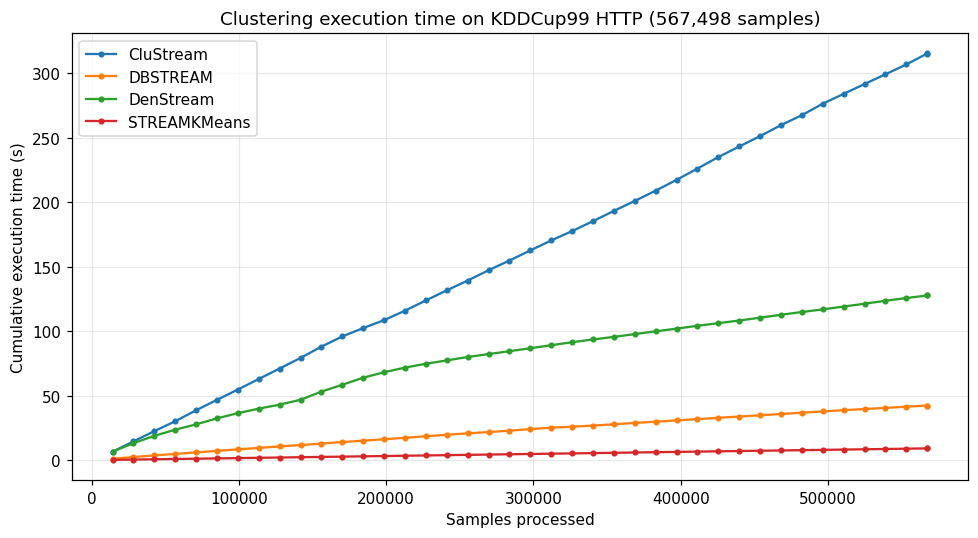

In [69]:
fig, ax = plt.subplots(figsize=(9, 5))
for name, g in df.groupby("model"):
    ax.plot(g["step"], g["time_s"], marker=".", label=name)
ax.set_xlabel("Samples processed")
ax.set_ylabel("Cumulative execution time (s)")
ax.set_title(f"Clustering execution time on KDDCup99 HTTP ({n_stream:,} samples)")
ax.legend()
plt.tight_layout()
plt.show()

## 5. RAM usage vs samples processed

The clusterer's own memory footprint over time. STREAMKMeans stays flat (fixed centroids), while micro-cluster / density methods (CluStream, DBSTREAM, DenStream) grow as they retain summaries of the stream.

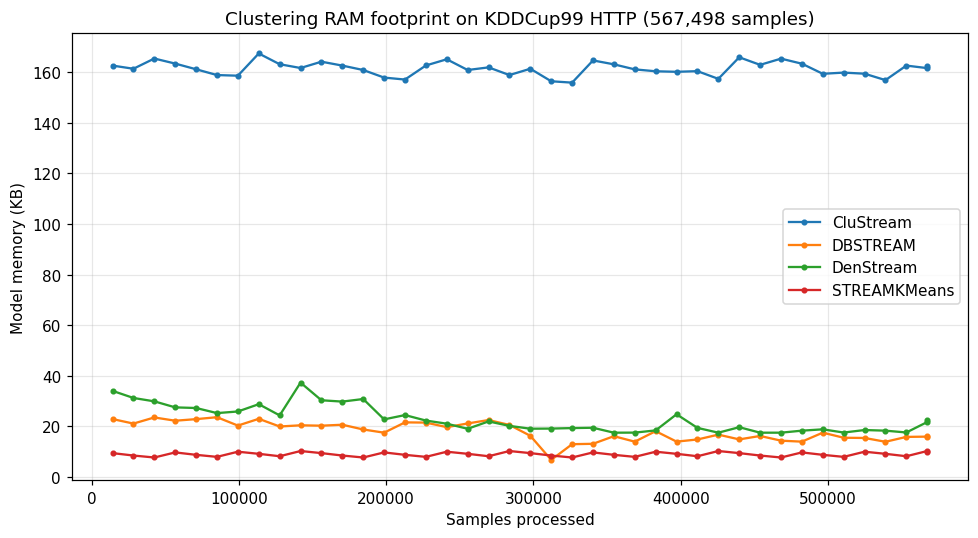

In [70]:
fig, ax = plt.subplots(figsize=(9, 5))
for name, g in df.groupby("model"):
    ax.plot(g["step"], g["memory_kb"], marker=".", label=name)
ax.set_xlabel("Samples processed")
ax.set_ylabel("Model memory (KB)")
ax.set_title(f"Clustering RAM footprint on KDDCup99 HTTP ({n_stream:,} samples)")
ax.legend()
plt.tight_layout()
plt.show()

## 6. Summary table

Final numbers per clusterer: total time, throughput (samples/second — the number that matters for a live stream), and final RAM.

In [71]:
summary = (
    df.sort_values("step")
    .groupby("model")
    .agg(
        total_time_s=("time_s", "max"),
        final_memory_bytes=("memory_bytes", "last"),
    )
)
summary["throughput_samples_per_s"] = n_stream / summary["total_time_s"]
summary["final_memory"] = summary["final_memory_bytes"].apply(humanize_bytes)

summary_view = summary[
    ["total_time_s", "throughput_samples_per_s", "final_memory"]
].sort_values("throughput_samples_per_s", ascending=False)
summary_view.round(3)

,total_time_s,throughput_samples_per_s,final_memory
model,,,
STREAMKMeans,9.177,61841.892,9.56 KiB
DBSTREAM,42.412,13380.501,15.89 KiB
DenStream,127.735,4442.788,22.39 KiB
CluStream,315.337,1799.653,162.72 KiB


## Takeaways

- In a real project you stream events through **one** clusterer with `predict_one` / `learn_one`; this notebook runs several only to compare resource profiles.
- **Execution time** should grow roughly linearly with samples — that's what makes a clusterer viable for an unbounded stream. Throughput (samples/s) is the practical number to watch. STREAMKMeans is by far the fastest; CluStream, which maintains many micro-clusters, is the most expensive.
- **RAM** stays flat for centroid methods (STREAMKMeans) but grows for micro-cluster / density methods (CluStream, DBSTREAM, DenStream) that retain summaries of the data — the trade-off against their flexibility in discovering cluster shape and count.
- Everything comes straight from `evaluate.iter_progressive_val_score` — no extra profiling library needed. For whole-process RAM (rather than just the model object) wrap the loop with `psutil` or `tracemalloc`.